# Лекція 5. Локальний деплоймент і оптимізація моделей

Демо до лекції. Усі моделі в цьому ноутбуці запускаються **локально** через [Ollama](https://ollama.com), їх використання відбувається через HTTP-запити.

## 0. Налаштування середовища

### 0.0. Імпортуємо бібліотеки

In [4]:
import json
import subprocess
import sys
import time
import urllib.request

OLLAMA_URL = "http://localhost:11434"

### 0.1. Встановлюємо й запускаємо Ollama

Локально цю клітинку можна просто виконати: вона нічого не зробить.

In [5]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

if IN_COLAB:
    !sudo apt-get -qq install -y zstd > /dev/null
    !curl -fsSL https://ollama.com/install.sh | sh
    subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    time.sleep(5)

Running in Colab: True
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


### 0.2. Перевіряємо, що Ollama працює

Ollama — це HTTP-сервер на порту 11434. Функція `ollama()` надсилає йому запит і повертає відповідь як словник Python; якщо сервер працює, побачимо його версію.

In [6]:
def ollama(path, body=None, timeout=900):
    """POST-запит до Ollama (або GET, якщо body=None); повертає розібраний JSON."""
    data = json.dumps(body).encode() if body is not None else None
    req = urllib.request.Request(OLLAMA_URL + path, data=data, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        return json.load(resp)


print("Ollama version:", ollama("/api/version")["version"])

Ollama version: 0.40.16


## 1. Base, Instruct і Thinking

Порівнюємо три поведінки однієї й тієї самої моделі Qwen3 1.7B:
- **Base-модель** пройшла лише попереднє тренування: вона вміє передбачати наступний токен в інтернет-текстах, але не вміє відповідати на питання як асистент.
- **Instruct-модель** додатково донавчили на прикладах «інструкція → відповідь» у форматі діалогу.
- **Thinking** — режим, у якому Instruct-модель перед відповіддю генерує ланцюжок міркувань.

### 1.0. Завантажуємо моделі

Беремо одну й ту саму модель Qwen3 1.7B у двох версіях:
- **Base** — [Qwen3-1.7B-Base](https://huggingface.co/Qwen/Qwen3-1.7B-Base) у форматі GGUF (Q4_K_M) з Hugging Face;
- **Instruct** — офіційна [qwen3:1.7b](https://ollama.com/library/qwen3) з каталогу Ollama; вона ж уміє працювати в режимі міркування.

Перше завантаження займає кілька хвилин.

In [7]:
BASE_MODEL = "hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M"
INSTRUCT_MODEL = "qwen3:1.7b"

for m in (BASE_MODEL, INSTRUCT_MODEL):
    print("pull", m, "→", ollama("/api/pull", {"model": m, "stream": False})["status"])

pull hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M → success
pull qwen3:1.7b → success


### 1.1. Допоміжні функції

Нам вистачить двох ендпойнтів Ollama:
- `/api/generate` з `"raw": true` — передає моделі текст як є, **без chat template**;
- `/api/chat` — приймає список повідомлень і сам загортає їх у chat template моделі.

У Qwen3 режим міркування вмикається параметром `think`. З `think=True` модель спершу генерує ланцюжок міркувань (Ollama повертає його окремим полем `message.thinking`), а вже потім — відповідь. Функція `compare_thinking()` запускає запит в обох режимах і показує відповідь, кількість згенерованих токенів і час.

In [8]:
def generate_raw(model, prompt, max_tokens=120):
    """Продовження тексту без chat template — так «бачить» запит Base-модель."""
    r = ollama("/api/generate", {
        "model": model, "prompt": prompt, "raw": True, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })
    return r["response"]


def chat(model, prompt, think=False, max_tokens=3000):
    """Один запит у форматі діалогу; think=True вмикає режим міркування."""
    return ollama("/api/chat", {
        "model": model, "messages": [{"role": "user", "content": prompt}],
        "think": think, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })


def compare_thinking(prompt):
    for think in (False, True):
        r = chat(INSTRUCT_MODEL, prompt, think=think)
        msg = r["message"]
        print(f"=== think={think} | токенів: {r['eval_count']} | генерація: {r['eval_duration'] / 1e9:.1f} с")
        if msg.get("thinking"):
            print(f"--- міркування ({len(msg['thinking'])} символів), початок:")
            print(msg["thinking"][:600], "…")
        print("--- відповідь:")
        print(msg["content"])
        print()

### 1.2. Base: модель просто продовжує текст

Поставимо Base- та Instruct-моделі однакове питання.

In [9]:
QUESTION = "Яка столиця Франції?"

In [10]:
print(generate_raw(BASE_MODEL, QUESTION))

 Як називається найбільша річка Франції? Як називається найбільша річка Франції, яка розташована в Північній Америці? Як називається найбільша річка Франції, яка розташована в Півдні Франції? Як називається найбільша р


Для Base-моделі «Яка столиця Франції?» схоже на початок списку питань вікторини — тож вона продовжує цей список, а не відповідає.

### 1.3. Instruct: модель відповідає на питання

In [11]:
print(chat(INSTRUCT_MODEL, QUESTION)["message"]["content"])

Столиця Франції — це **Париж**.


### 1.4. Instruct проти Thinking: багатокрокова задача

In [12]:
compare_thinking(
    "У кошику 3 яблука. Марія поклала туди ще 2 пакети по 4 яблука, "
    "а потім зʼїла 2 яблука. Скільки яблук у кошику?"
)

=== think=False | токенів: 252 | генерація: 2.1 с
--- відповідь:
Розглянемо ситуацію крок за кроком:

1. **У кошику 3 яблука.**  
2. **Марія поклала туди ще 2 пакети по 4 яблука.**  
   - Кожен пакет містить 4 яблука, тому:
     $$
     2 \text{ пакети} \times 4 \text{ яблука} = 8 \text{ яблука}
     $$
   - Значить, після додавання пакетів у кошик буде:
     $$
     3 + 8 = 11 \text{ яблука}
     $$
3. **Марія зʼїла 2 яблука.**  
   - Після з’ївання:
     $$
     11 - 2 = 9 \text{ яблука}
     $$

**Відповідь:**  
$$
\boxed{9}
$$

=== think=True | токенів: 569 | генерація: 5.1 с
--- міркування (1410 символів), початок:
Okay, let's see. So the problem is about Maria putting some apples in a basket and then eating some. Let me break it down step by step.

First, the basket starts with 3 apples. Then, Maria adds 2 packages, each containing 4 apples. So, I need to calculate how many apples she adds in total. Each package has 4 apples, and there are 2 packages. So that's 2 times 4, which i

Обидва режими відповідають правильно, але з міркуванням модель генерує в кілька разів більше токенів — а користувач бачить відповідь лише після них. Зверніть увагу: міркує модель англійською, хоча питання українською.

### 1.5. Міркування не гарантують правильності

In [13]:
compare_thinking("Скільки разів літера «р» трапляється в слові «трансформер»?")

=== think=False | токенів: 227 | генерація: 2.0 с
--- відповідь:
Щоб визначити, скільки разів літера **«р»** трапляється в слові **«трансформер»**, зробимо так:

Слово: **трансформер**

Розбілем його на складні слова:

- **транс**  
- **формер**

Тепер зіштовхуємо літеру **«р»** в кожному з складних слів:

1. **транс** — не має літери «р»  
2. **формер** — має **1** відтінок «р» (відтінок «р» у слові **формер**)

Отже, літера **«р»** трапляється **1 раз** в слові **«трансформер»**.

**Відповідь: 1 раз.**

=== think=True | токенів: 659 | генерація: 6.0 с
--- міркування (1490 символів), початок:
Okay, let's see. The user is asking how many times the letter "р" appears in the word "трансформер". First, I need to make sure I know the correct spelling of the word. The word in question is "трансформер". Let me write it out: трансформер.

Now, I need to check each letter one by one. Let's start from the beginning. The first letter is "т" which is "t" in Ukrainian, but the question is about th

Правильна відповідь — 3 (т**р**ансфо**р**ме**р**), але мала модель помиляється в обох режимах. Чому так — подумайте самі (це питання до лабораторної роботи).

Спробуйте власні запити: де режим міркування справді допомагає, а де лише витрачає токени?

## 2. Квантизація з Quanto

Завантажимо ту саму модель у чотирьох варіантах — від оригінальних 16 біт до 2 біт — і подивимося, що квантизація змінює в памʼяті, швидкості та якості. Якість перевіримо трьома способами: перплексією, перекладом з автоматичними метриками й очима — на вільній генерації тексту.

**Quanto.** [Optimum Quanto](https://github.com/huggingface/optimum-quanto) — бібліотека квантизації від Hugging Face, один із бекендів [Optimum](https://huggingface.co/docs/optimum). У Transformers вона підключається через [`QuantoConfig`](https://huggingface.co/docs/transformers/quantization/quanto) і квантизує модель прямо під час завантаження, тому окремий файл з квантизованими вагами не потрібен. Квантизуються ваги лінійних шарів (`nn.Linear`) — у них більшість параметрів моделі, а ембединги, нормалізації та вихідний шар лишаються в 16 бітах.

| Варіант | Біт на вагу | Що це |
|---|---|---|
| fp16 | 16 | Оригінальні ваги, точка відліку |
| int8 | 8 | 8-бітні цілі числа з масштабом |
| int4 | 4 | 4-бітні цілі числа, ваги діляться на блоки з власними масштабами |
| int2 | 2 | 2-бітні цілі числа — лише 4 можливі значення на вагу; тут модель має зламатися |

**Обчислення.** Множити числа в цих форматах напряму T4 не вміє, тому перед множенням ваги розпаковуються в 16 біт. Тому памʼяті потрібно менше, а от генерація часто **не прискорюється**, а то й сповільнюється.

**Де запускати.** Секцію запускаємо **в Google Colab на GPU T4** (Runtime → Change runtime type → T4 GPU). Беремо формат **fp16**, а не bf16: T4 не підтримує bf16 апаратно, а для запуску готової моделі різниця між ними практично непомітна.

### 2.0. Встановлюємо бібліотеки й перевіряємо GPU

In [14]:
%pip uninstall -y -q diffusers  # optimum-quanto імпортує diffusers, якщо він є; передвстановлена в Colab версія несумісна з його torchao
%pip install -q "transformers==5.20.1" "accelerate==1.15.0" "optimum-quanto==0.2.7" "evaluate==0.4.6" "sacrebleu==2.6.0"

In [15]:
import gc
import time
from types import SimpleNamespace

import evaluate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from optimum.quanto.library.extensions import get_extension
from transformers import AutoModelForCausalLM, AutoTokenizer, QuantoConfig

assert torch.cuda.is_available(), "Увімкніть GPU: Runtime → Change runtime type → T4 GPU"
DEVICE = "cuda"
DTYPE = torch.float16
print("GPU:", torch.cuda.get_device_name())


def unpack_weights(packed, bits):
    """Розпаковує 4- чи 2-бітні значення, по кілька упакованих в одному байті."""
    values_per_byte = 8 // bits
    mask = 2**bits - 1
    return torch.cat([(packed >> (bits * i)) & mask for i in range(values_per_byte)]).to(torch.uint8)


# Quanto на GPU компілює власні CUDA-ядра, розраховані на A100 і новіші; на T4 ця компіляція падає.
# На T4 з усіх цих ядер потрібна лише розпаковка int4/int2-ваг, тож підставляємо її версію на чистому PyTorch.
if torch.cuda.get_device_capability()[0] < 8:
    get_extension("quanto_cuda")._lib = SimpleNamespace(unpack=unpack_weights)

GPU: Tesla T4


### 2.1. Модель і варіанти квантизації

Беремо [Qwen3-4B-Instruct-2507](https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507) — сильнішу модель того ж сімейства, що й у секції 1: 4B параметрів, лише Instruct-режим без міркувань. У fp16 вона займає ~8 GB і вміщається в T4 з його 16 GB.

In [16]:
MODEL_ID = "Qwen/Qwen3-4B-Instruct-2507"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

VARIANTS = {
    "fp16": None,
    "int8": QuantoConfig(weights="int8"),
    "int4": QuantoConfig(weights="int4"),
    "int2": QuantoConfig(weights="int2"),
}

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.38k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

### 2.2. Що міряємо

**Перплексія** — стандартна автоматична метрика якості квантизації (нею міряє, зокрема, llama.cpp). Модель читає фіксований текст, і для кожного токена ми дивимося, яку ймовірність вона йому давала. Перплексія — це, грубо кажучи, з якої кількості варіантів модель у середньому «вагалася»: чим вона менша, тим краще модель знає мову й тему. Еталонних відповідей тут не потрібно, а число змінюється плавно, тому видно навіть невеликі втрати. Порівнювати перплексію можна лише в межах однієї мови: англійська й українська токенізуються по-різному.

**Переклад EN → UK** — реалістичне завдання з генерацією тексту, для якого є еталонні переклади. Порівнюємо переклад моделі з еталоном двома стандартними метриками з бібліотеки [Evaluate](https://huggingface.co/docs/evaluate):
- [**chrF**](https://github.com/huggingface/evaluate/blob/main/metrics/chrf/README.md) — наскільки збігаються послідовності символів (0–100);
- [**BLEU**](https://github.com/huggingface/evaluate/tree/main/metrics/sacrebleu) — наскільки збігаються послідовності слів (0–100). Сувора метрика: синонім чи інший порядок слів уже знижують бал.

**Вільна генерація** — лист, пояснення, план, код. Тут еталону немає, тож оцінюємо очима в 2.5.

Крім якості, для кожного варіанта записуємо **памʼять моделі** на GPU, **пік VRAM** і **швидкість генерації** (tokens/s).

In [17]:
PPL_TEXT = {
    "English": (
        "Photosynthesis is the process by which green plants, algae and some bacteria turn light energy into "
        "chemical energy. It takes place mainly in the leaves, inside small structures called chloroplasts, which "
        "contain the green pigment chlorophyll. Chlorophyll absorbs sunlight, and the plant uses this energy to "
        "combine carbon dioxide from the air with water from the soil. The result is glucose, a sugar that the "
        "plant uses for growth and as a store of energy, and oxygen, which is released into the atmosphere. "
        "Almost all life on Earth depends on photosynthesis: it produces the oxygen we breathe and forms the "
        "basis of most food chains."
    ),
    "Українська": (
        "Фотосинтез — це процес, під час якого зелені рослини, водорості та деякі бактерії перетворюють енергію "
        "світла на хімічну енергію. Він відбувається переважно в листках, усередині маленьких структур, які "
        "називають хлоропластами і які містять зелений пігмент хлорофіл. Хлорофіл поглинає сонячне світло, і "
        "рослина використовує цю енергію, щоб поєднати вуглекислий газ із повітря з водою із ґрунту. У результаті "
        "утворюються глюкоза — цукор, який рослина використовує для росту і як запас енергії, — та кисень, що "
        "виділяється в атмосферу. Майже все життя на Землі залежить від фотосинтезу: він дає кисень, яким ми "
        "дихаємо, і лежить в основі більшості харчових ланцюгів."
    ),
}

TRANSLATION = [
    # (речення англійською, еталонний переклад)
    ("The meeting has been moved to Thursday at three o'clock.", "Зустріч перенесли на четвер на третю годину."),
    ("Please send me the report by the end of the day.", "Будь ласка, надішліть мені звіт до кінця дня."),
    ("The library is closed on Sundays and public holidays.", "Бібліотека не працює в неділю та у святкові дні."),
    ("Our team fixed the bug, but the tests are still failing.", "Наша команда виправила помилку, але тести все ще не проходять."),
    ("It is going to rain tomorrow, so take an umbrella.", "Завтра буде дощ, тож візьміть парасольку."),
    ("The new model is smaller, but it answers almost as well as the old one.", "Нова модель менша, але відповідає майже так само добре, як стара."),
    ("I would like to book a table for two for seven o'clock tonight.", "Я хотів би забронювати столик на двох на сьому вечора."),
    ("The price includes breakfast and free Wi-Fi.", "У вартість входять сніданок і безкоштовний Wi-Fi."),
    ("Students must submit their lab work before the deadline.", "Студенти мають здати лабораторну роботу до кінцевого терміну."),
    ("If the server does not respond, restart it and check the logs.", "Якщо сервер не відповідає, перезапустіть його й перевірте логи."),
]
TRANSLATE_PROMPT = "Translate the following sentence into Ukrainian. Output only the translation.\n\n{}"

GEN_PROMPTS = [
    "Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.",
    "Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.",
    "Explain in three sentences why the sky is blue.",
    "Склади план підготовки до іспиту з програмування на 5 днів, по одному пункту на день.",
    "Write a Python function that checks whether a string is a palindrome.",
]

### 2.3. Проганяємо всі варіанти

Дві допоміжні функції — перплексія тексту й генерація відповіді — і цикл по варіантах: завантажуємо модель, міряємо все потрібне, звільняємо памʼять. Займає кілька хвилин на варіант.

In [18]:
def perplexity(model, text):
    """exp(середня похибка передбачення наступного токена) на фіксованому тексті."""
    ids = tokenizer(text, return_tensors="pt").input_ids.to(DEVICE)
    with torch.no_grad():
        loss = model(ids, labels=ids).loss
    return float(torch.exp(loss))


def generate(model, prompt, max_new_tokens):
    """Відповідь без випадковості; повертає текст, кількість нових токенів і час генерації."""
    text = tokenizer.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(DEVICE)
    torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    torch.cuda.synchronize()
    new_tokens = output[0, inputs.input_ids.shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip(), len(new_tokens), time.perf_counter() - start


records = {}
for name, config in VARIANTS.items():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE, quantization_config=config)

    r = {"памʼять моделі, GB": torch.cuda.memory_allocated() / 1e9}
    for lang, text in PPL_TEXT.items():
        r[f"перплексія, {lang}"] = perplexity(model, text)
    r["переклади"] = [generate(model, TRANSLATE_PROMPT.format(src), 80)[0] for src, _ in TRANSLATION]
    generations = [generate(model, prompt, 200) for prompt in GEN_PROMPTS]
    r["генерації"] = [text for text, _, _ in generations]
    r["tokens/s"] = sum(n for _, n, _ in generations) / sum(s for _, _, s in generations)
    r["пік VRAM, GB"] = torch.cuda.max_memory_allocated() / 1e9
    records[name] = r
    print(f"{name}: готово")

    del model

model.safetensors.index.json:   0%|          | 0.00/32.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

fp16: готово


... (2 outputs left out)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int4: готово


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int2: готово


### 2.4. Памʼять, швидкість і автоматичні метрики

In [19]:
chrf = evaluate.load("chrf")
bleu = evaluate.load("sacrebleu")
references = [[ref] for _, ref in TRANSLATION]

summary = pd.DataFrame({
    name: {
        "памʼять моделі, GB": r["памʼять моделі, GB"],
        "пік VRAM, GB": r["пік VRAM, GB"],
        "tokens/s": r["tokens/s"],
        **{f"перплексія, {lang}": r[f"перплексія, {lang}"] for lang in PPL_TEXT},
        "chrF перекладу": chrf.compute(predictions=r["переклади"], references=references)["score"],
        "BLEU перекладу": bleu.compute(predictions=r["переклади"], references=references)["score"],
    }
    for name, r in records.items()
}).T.round(2)
summary

,"памʼять моделі, GB","пік VRAM, GB",tokens/s,"перплексія, English","перплексія, Українська",chrF перекладу,BLEU перекладу
fp16,8.04,8.64,16.48,2.67,2.40,55.22,23.71
int8,4.42,5.01,5.98,2.67,2.40,58.25,26.17
int4,2.73,3.32,2.95,2.81,2.76,55.34,29.79
int2,1.81,2.39,3.01,60091.86,34451480.00,0.19,0.12


Перплексія для кожної мови окремо. Вісь — логарифмічна: інакше на одному графіку не помістилися б і кілька одиниць, і сотні.

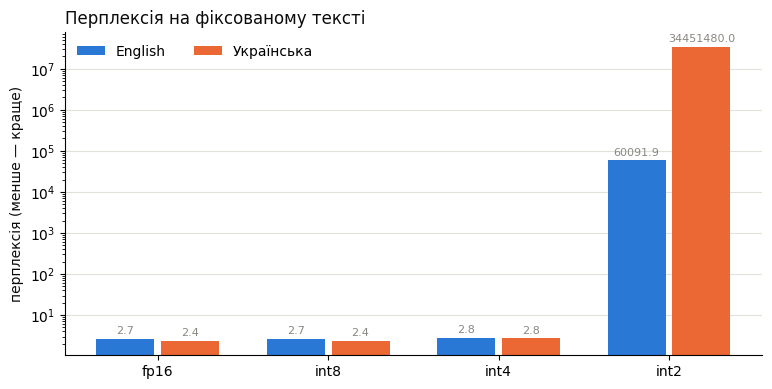

In [20]:
LANG_COLORS = {"English": "#2a78d6", "Українська": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

variants = list(records)
x = np.arange(len(variants))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, lang in enumerate(PPL_TEXT):
    values = summary[f"перплексія, {lang}"].values
    bars = ax.bar(x + (i - 0.5) * width, values, width - 0.04, color=LANG_COLORS[lang], label=lang)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], fontsize=8, color=MUTED, padding=2)
ax.set_yscale("log")
ax.set_xticks(x, variants)
ax.set_ylabel("перплексія (менше — краще)", color=INK)
ax.set_title("Перплексія на фіксованому тексті", loc="left", color=INK)
ax.legend(frameon=False, ncols=2, loc="upper left")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

Переклади всіх варіантів поруч з еталоном:

In [21]:
translations = pd.DataFrame({"еталон": [ref for _, ref in TRANSLATION]}, index=[src for src, _ in TRANSLATION])
for name, r in records.items():
    translations[name] = r["переклади"]
translations

,еталон,fp16,int8,int4,int2
The meeting has been moved to Thursday at three o'clock.,Зустріч перенесли на четвер на третю годину.,"Зустріч була перенесена на четвер, о 15 годин.","Зустріч перенесли на четвер, о 15 годин.","Зустріч була перенесена на четвер, о 15 годин.",`` takenosthawkhhhawkoft0houghth``t`\'uleh'thh...
Please send me the report by the end of the day.,"Будь ласка, надішліть мені звіт до кінця дня.",Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,takenawns between't```````````````````h``` \`e...
The library is closed on Sundays and public holidays.,Бібліотека не працює в неділю та у святкові дні.,Бібліотека закривається у неділі та дні відпоч...,Бібліотека закривається у неділі та дні відпоч...,Бібліотека відкрита тільки з 1 по 7.,`ever �house �take caught}}house0}0 taken take...
"Our team fixed the bug, but the tests are still failing.","Наша команда виправила помилку, але тести все ...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тести все ще н...",fil}'sand ever0'f}'h \n'}'}''}'' \n' \n \n ...
"It is going to rain tomorrow, so take an umbrella.","Завтра буде дощ, тож візьміть парасольку.","Завтра піде дощ, тому взміть засіб.","Завтра піде дощ, тому взміть з собою парасольку.","Завтра буде дощ, тому взміть засіб.",}again \蚊} taken \neverh. \n \nagain \n \n...
"The new model is smaller, but it answers almost as well as the old one.","Нова модель менша, але відповідає майже так са...","Новий модель менший, але відповідає почти так ...","Новий модель менший, але відповідає приблизно ...","Новий модель менший, але відповідає почти так ...",fil��''}\n0. between'h ’h ` between betweenfec...
I would like to book a table for two for seven o'clock tonight.,Я хотів би забронювати столик на двох на сьому...,Я бажаю забронювати стіл для двох на сім годин...,Я бажаю забронювати стіл для двох на сім годин...,Я б хотів зареєструвати стіл для двох на 7 год...,``ever``always```comeight`[\n`letic touched`ev...
The price includes breakfast and free Wi-Fi.,У вартість входять сніданок і безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та вільний Wi-Fi.,.前所eterminefilosterone0 00 \00 \tt011011OFF00e...
Students must submit their lab work before the deadline.,Студенти мають здати лабораторну роботу до кін...,Студенти повинні подати свою лабораторну робот...,Студенти повинні подати свою лабораторну робот...,Студенти повинні відправляти лабораторну робот...,he $everearned a0001100evers \n0\n\nhehe0'tou...
"If the server does not respond, restart it and check the logs.","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...",ever. taken againoughtbetweenhtonhhofthhbetwee...


### 2.5. Сліпе порівняння: fp16 проти int4

Автоматичні метрики показали, наскільки int4 відрізняється від fp16 у числах. Тепер перевірмо очима — так, як це роблять оцінювачі-люди: для кожного запиту показуємо дві відповіді, fp16 та int4, **у випадковому порядку й без підписів**. Ваше завдання — обрати кращу.

In [22]:
rng = np.random.default_rng(0)
BLIND_ORDER = [rng.permutation(["fp16", "int4"]) for _ in GEN_PROMPTS]

for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for label, name in zip("AB", BLIND_ORDER[i]):
        display(Markdown(f"**Відповідь {label}:**\n\n{records[name]['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**Відповідь A:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**Відповідь B:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

**Відповідь A:**

Квантизація нейромережі — це процес зменшення точності ваг між нейронами в мережі, щоб зменшити об’єм пам’яті та швидкість обчислень. Вона полягає у заміні дробових чисел (наприклад, з плаваючою комою) на цілі числа (наприклад, з кількома бітами). Це дозволяє запускати мережі на пристроях з обмеженою відповідністю, таких як мобільні телефони або IoT-апарати. Насправді, квантизація не втрачає повно

**Відповідь B:**

Квантизація нейромережі — це процес зменшення точності ваг (зв'язків між нейронами) до тих рівнів, що можна зберігати в комп'ютері з меншою відповідністю до об’ємних ресурсів. Це робиться для зменшення об’єму пам’яті та швидкості обчислень. Наприклад, ваги можуть бути зображено як цілі числа (наприклад, 8 біт) замість дробових чисел. Це зручно для використання на пристроях з обмеженими ресурс

... (5 outputs left out)

**Відповідь B:**

Ось чіткий і практичний план підготовки до іспиту з програмування на 5 днів — по одному ключовому темі на день. Цей план призначений для студентів, які вивчають програмування на початковому або середньому рівні (наприклад, на мові Python, Java або C++), але може бути адаптований під будь-яку мову.

---

**День 1: Основні структури даних та їх використання**

- Повторити: змінні, типи даних, оператори, вирази.
- Вивчити: списки, кортежі, слов

---
#### Запит 5: Write a Python function that checks whether a string is a palindrome.

**Відповідь A:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**Відповідь B:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

Для кожного запиту запишіть **"A"** або **"B"** — яка відповідь краща, або **"="**, якщо однакові за якістю. Потім запустіть наступну клітинку, щоб дізнатися, де була яка модель.

In [23]:
VOTES = {1: "", 2: "", 3: "", 4: "", 5: ""}

In [24]:
if all(v in ("A", "B", "=") for v in VOTES.values()):
    rows = []
    for i, vote in VOTES.items():
        order = dict(zip("AB", BLIND_ORDER[i - 1]))
        rows.append({"запит": GEN_PROMPTS[i - 1], "A": order["A"], "B": order["B"],
                     "ваш вибір": "однаково" if vote == "=" else order[vote]})
    display(pd.DataFrame(rows))
    choices = [r["ваш вибір"] for r in rows]
    print(f"fp16 краща: {choices.count('fp16')}, int4 краща: {choices.count('int4')}, однаково: {choices.count('однаково')}")
else:
    print('Заповніть VOTES значеннями "A", "B" або "=" для всіх 5 запитів.')

Заповніть VOTES значеннями "A", "B" або "=" для всіх 5 запитів.


### 2.6. Відповіді всіх варіантів

Тепер, коли сліпе порівняння зроблено, — відповіді всіх варіантів з підписами, включно з int8 та int2. Еталону тут немає, тож читаємо самі.

In [25]:
for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for name, r in records.items():
        display(Markdown(f"**{name}:**\n\n{r['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**fp16:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**int8:**

Ось приклад короткого листа викладачеві:

---

**Дорогий [Ім’я викладача]!**

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу.  
Буду дуже вдячний за розуміння та гнучкість.

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Контактна інформація, якщо потрібно]

---

Цей лист короткий, виразний та відповідає формату прохання. Можна адаптувати під конкретну ситуацію.

**int4:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

**int2:**

°°h\ter°\n h hsd°°ampton \ \
 \
:
h h h h : had had had had had had again had had had had h bettb h hhtonhtonsd**leehtonhtonsdhtonhtonhtonhtonhtonhtonhton (%) nuts9 system \ \ rest  \} \} \n \ \ \ \  \ \ \ \ h \ \ \ h \ \ h \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \  \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ the \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

... (15 outputs left out)

**fp16:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int8:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int4:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**int2:**

\
 \'  
\' 
\' \ \ \ \ \\'\' \ \ \ \ \\' \\' \ OFF ** \ - [\'0 \'\'\'\'\'\' \' \ \ \ 
 
  \ 
5  \ \ \\ \ 
 
0 \ -  - - - - - - - - - - -  \ \ - - - - \  
\' \ \\'\' \\'\'    - - sent\'\'\'\'\n\'\' \ \ \ \ \ \ \ \ \ \ \ \ \ \ - - \ -  - -  -\'20\' \' - - - - - - - - - \ \' - -':
 - - - - - - - - - -   - - - - - - - - - - - - - - - - - - - - - -LOCK  \ -  \ -\' \ \ \   PRO \ - - - - - -

# Лабораторна робота №4
## Створення пар «запитання–відповідь» із навчального тексту

**Дата виконання:** 12.11.2026. **Результат:** локальний вебзастосунок із генерацією карток та сторінкою bench із методичних.

Розділи 0–2 вище — наданий виконаний демо-ноутбук: його код і збережені виходи залишено без змін.
Показники Quanto 4B із цього демо використано для аналізу теорії; вони не є новими вимірюваннями на RTX 5070.
Нижче наведено відповіді на 20 запитань, додаткові фактичні експерименти та власний звіт.
Власні дані зберігаються у `results/`, основні нові вимірювання — у `bench_results.csv`.
Звіт не стверджує, що збережене демо повторно запускалося в Google Colab у цій сесії.


In [101]:
from pathlib import Path
import json, csv, math
LAB4 = Path(globals().get('LAB4', '.'))
if not (LAB4 / 'results').exists():
    candidates = [Path.cwd()/'lab4', Path.cwd()/'ai_systems'/'lab4']
    LAB4 = next(p for p in candidates if (p/'results').exists())
def read_result(name):
    return json.loads((LAB4/'results'/name).read_text(encoding='utf-8'))
print('Джерела:', ', '.join(p.name for p in sorted((LAB4/'results').glob('*.json'))))


Джерела: base_table.json, extra_experiments.json, method_provenance.json, model_metadata.json, noise_ppl.json, quality_after.json, quality_before.json, small_model.json, tokenization.json, translation_metrics.json


## 0.1. Відповіді на теоретичні запитання

### 1. Чому модель помиляється з літерою «р»?
Модель передбачає токени, а не виконує посимвольний цикл. Токенізатор Qwen розбиває слово на 5 токенів: «т», «ран», «с», «форм», «ер», а не на 11 літер.
Літера «р» входить до кількох різних токенів; навичка продовження тексту не гарантує точного підрахунку їхніх символів.
Це сприяє помилкам, хоча токенізація сама по собі не робить правильний підрахунок неможливим.
Міркування теж генеруються статистично й не замінюють виконання коду. Правильний результат: **3**, позиції **2, 8, 11**.
Нижче — збережений фактичний результат токенізатора Qwen3-1.7B і незалежна перевірка Python.


In [102]:
t = read_result('tokenization.json')
print('Token IDs:', t['ids'])
print('Кількість токенів:', len(t['ids']))
word = 'трансформер'
print('Символи:', list(word))
print('Кількість р:', word.count('р'))
print('Позиції:', [i+1 for i,c in enumerate(word) if c == 'р'])
# Для повторного отримання токенів (pip install tokenizers):
# from tokenizers import Tokenizer
# tokenizer = Tokenizer.from_pretrained('Qwen/Qwen3-1.7B')
# print(tokenizer.encode(word).ids)


Token IDs: [1792, 34582, 2247, 56619, 7599]
Кількість токенів: 5
Символи: ['т', 'р', 'а', 'н', 'с', 'ф', 'о', 'р', 'м', 'е', 'р']
Кількість р: 3
Позиції: [2, 8, 11]


### 2. Як змінюються перплексія та переклад від fp16 до int2?

| Варіант | PPL EN | PPL UK | chrF | BLEU |
|---|---:|---:|---:|---:|
| fp16 | 2.67 | 2.40 | 55.22 | 23.71 |
| int8 | 2.67 | 2.40 | 58.25 | 26.17 |
| int4 | 2.81 | 2.76 | 55.34 | 29.79 |
| int2 | 60091.86 | 34451480.00 | 0.19 | 0.12 |

Найбільший стрибок — **int4 → int2**: перплексія зростає на порядки, переклад руйнується.
Невелике підвищення BLEU/chrF в int8/int4 не доводить загального покращення моделі: є лише 10 речень, а метрики залежать від збігу з одним еталоном.

### 3. Чи однаково змінюється PPL для двох мов?
Ні. Для int4 відносно fp16 англійська зростає приблизно на **5.2%**, українська — на **15%**.
У int2 деградація української також набагато більша. Це узгоджується з тезою лекції про вразливість мов із нелатинською абеткою.
Порівнюю **відносну зміну всередині кожної мови**, а не абсолютну PPL між мовами. Ці два короткі тексти не дають узагальнення на всі мовні задачі.

### 4. Оцінювання відповідей A/B і автоматичні метрики
Ретроспективна оцінка наданих відповідей: **1 — B; 2 — =; 3 — =; 4 — =; 5 — B**.
У першій парі B коротша та не містить невдалого звертання «Увага, викладаче!». У другій обидві відповіді мають мовні помилки й обрізані.
Обидва пояснення синього неба придатні. Обидва плани підготовки обірвані на першому дні через ліміт генерації.
У п’ятій парі B має завершений приклад викликів, тоді як A завершується незакінченим `print(is_palindrome`.
Майже однаковий chrF fp16/int4 не відображає цих відмінностей: він вимірював переклади, а ці 5 промптів перевіряють інші задачі.
Це оцінка збережених відповідей, виконана під час підготовки роботи, **не незалежний сліпий експеримент користувача**.

### 5. Правильний переклад іншими словами
У таблиці int8: «Зустріч перенесли на четвер, о 15 годин.» проти еталона «Зустріч перенесли на четвер на третю годину.».
Для звичайного денного часу це передає той самий зміст, хоча формулювання «о 15 годині» природніше, а англійське речення саме по собі не уточнює AM/PM.
Інший приклад — «Надішліть мені звіт до кінця дня.»: основний зміст збережено, але втрачено ввічливе «будь ласка».
BLEU рахує збіги словесних n-грам і штрафує перефразування; chrF порівнює символьні n-грами та краще переносить морфологічні відмінності, але теж не перевіряє зміст.
Нижче окремо пораховано метрики для першої пари; це sentence-level оцінка, а не corpus BLEU таблиці 2.4.


In [103]:
m = read_result('translation_metrics.json')
print('Еталон:', m['reference'])
print('Переклад:', m['hypothesis'])
print('sentence BLEU:', round(m['bleu'], 2), 'chrF:', round(m['chrf'], 2))


Еталон: Зустріч перенесли на четвер на третю годину.
Переклад: Зустріч перенесли на четвер, о 15 годин.
sentence BLEU: 31.56 chrF: 69.29


### 6. Пам’ять і швидкість
За таблицею 2.4 пам’ять ваг/тензорів зменшилась із 8.04 GB до 4.42, 2.73, 1.81 GB: відповідно **1.82×, 2.95×, 4.44×**.
Не всі тензори квантуються; масштаби, зсуви та службові структури теж займають пам’ять. Частина шарів лишається у FP16.
У цьому запуску Quanto генерація **сповільнилася**: 16.48 → 5.98 → 2.95 → 3.01 токенів/с.
Менша кількість бітів не гарантує швидкості: розпакування/деквантизація та реалізація ядер можуть переважити економію передачі ваг.
Не переносимо ці швидкості на оптимізовані GGUF-ядра Ollama — їх виміряно окремо.

### 7. Чому Base генерує нові запитання? Як отримати відповідь?
Base навчена продовжувати текст і не має такого самого інструкційного налаштування, як Instruct.
Окреме питання може бути початком списку вікторини. Few-shot приклади задають продовження у потрібному форматі.
Перший перевірений шаблон «Запитання/Відповідь» дав неправильне «Паризька.»; сам few-shot не гарантує правильності.
Табличний шаблон нижче дав **«Париж»**. Збережено обидва фактичні результати; `raw=True` вимикає chat template, зупинка на новому рядку обмежує продовження.


In [104]:
b = read_result('base_table.json')
print(b['prompt'])
print('Продовження Base:', b['result']['response'])
print('Токенів:', b['result']['eval_count'])
# Відтворення через helper з app/extra_experiments.py:
# call('/api/generate', {'model': BASE_MODEL, 'prompt': b['prompt'], 'raw': True,
#      'stream': False, 'options': {'temperature': 0, 'seed': 1,
#      'num_predict': 20, 'stop': ['\n']}})


Країна | Столиця
Німеччина | Берлін
Італія | Рим
Іспанія | Мадрид
Франція |
Продовження Base:  Париж
Токенів: 4


### 8. Вартість міркувань у розділі 1.4
У **наданому ноутбуці**, а не в ілюстративній таблиці лекції: без міркувань **252 токени, 2.1 с**; з міркуваннями **569 токенів, 5.1 с**.
Разом це на 317 токенів і 3.0 с більше: **2.26× токенів, 2.43× часу**. Це різниця загальних генерацій, а не точна кількість лише прихованих токенів: текст фінальної відповіді теж різний.
Модель міркує англійською через розподіл мов у навчанні й мовні шаблони reasoning-даних; мова внутрішнього тексту не зобов’язана збігатися з мовою питання.

### 9. Задача, де thinking допоміг
У новому локальному запуску Qwen3-1.7B на запит «У слові «трансформер» скільки літер «р»? Відповідай лише числом.»
без thinking відповіла **2**, з thinking — **3**. Це не суперечить невдачі в демо: відрізняються формулювання, середовище виконання й виходи генерації.
Той самий режим не гарантує успіху на інших задачах: на задачі про 5 машин обидві відповіді були неправильні, а складний запит про кульки в thinking досяг ліміту токенів.


In [105]:
e = read_result('extra_experiments.json')
p = next(p for p in e['thinking'] if 'трансформер' in p['prompt'])
print('Промпт:', p['prompt'])
for mode in ['False', 'True']:
    r = p[mode]
    print('think='+mode, 'відповідь:', r['message']['content'],
          'токенів:', r['eval_count'], 'генерація, с:', round(r['eval_duration']/1e9, 3))


Промпт: У слові «трансформер» скільки літер «р»? Відповідай лише числом.
think=False відповідь: 2 токенів: 2 генерація, с: 0.007
think=True відповідь: 3 токенів: 497 генерація, с: 1.547


### 10. Навіщо temperature=0 і seed=1?
Нульова температура прибирає випадкове семплювання на користь найбільш імовірного продовження; seed фіксує генератор випадкових чисел там, де він використовується.
Це полегшує порівняння моделей і квантизацій. На різному обладнанні, версіях ядер, при паралельному виконанні чи чисельних нічиїх повна побітова відтворюваність не гарантується.

### 11. Чому fp16, а не bf16 на T4?
T4 має compute capability **(7, 5)** і не підтримує нативні BF16 Tensor Core операції. FP16 є практичним спільним форматом для цього демо.
У Colab перевіряється `torch.cuda.get_device_capability()`. На локальній RTX 5070 результат інший; він збережений у результатах додаткового експерименту.

### 12. Кількість параметрів і пам’ять FP16
За метаданими `/api/show`: **4 022 468 096** параметрів. За формулою `P × bits / 8`: **8.044936192 GB**, або близько **7.49 GiB**.
Це узгоджується з **8.04 GB** у таблиці 2.4; GB і GiB не слід змішувати.


In [106]:
P = 4022468096
print('FP16:', P*2/1e9, 'GB;', round(P*2/2**30, 3), 'GiB')
print('GPU capability нового експерименту:', read_result('small_model.json')['capability'])


FP16: 8.044936192 GB; 7.492 GiB
GPU capability нового експерименту: [12, 0]


### 13. Що таке перплексія? Експеримент із випадковим порядком слів
`PPL = exp(mean(-log p(x_t | x_<t)))`: експонента середньої втрати передбачення наступного токена. Нижче — краща передбачуваність фіксованого тексту.
Абсолютні значення між англійською й українською не зіставляємо як рейтинг знання мов: різняться токенізація, текст і частотність одиниць.
Для Qwen3-4B-Instruct-2507 FP16 використано той самий український текст із демо та перемішано його слова з `random.Random(42)`.
Частотний склад слів збережено, синтаксичні та смислові зв’язки порушено; тому очікуємо більшу PPL. Нижче — фактичні значення, не прогноз.
Відтворення: `app/noise_experiment.py`.


In [107]:
n = read_result('noise_ppl.json')
print('Модель:', n['model'], n['dtype'])
for key,value in n['ppl'].items(): print(key, round(value, 4))
print('Зростання:', round(n['ppl']['shuffled']/n['ppl']['original'], 2), 'раза')
print('Початок перемішаного тексту:', n['texts']['shuffled'][:180])


Модель: Qwen/Qwen3-4B-Instruct-2507 fp16
original 2.4012
shuffled 13.9905
Зростання: 5.83 раза
Початок перемішаного тексту: він — рослина водорості зелений структур, — запас світла цукор, використовує та водою виділяється з дихаємо, із рослина росту і У кисень, щоб містять ланцюгів. як лежить рослини, п


### 14. Чому пік VRAM більший за пам’ять моделі?
Окрім ваг потрібні KV-кеш, активації поточного кроку, буфери attention/деквантизації, logits, тимчасові тензори та робоча пам’ять ядер.
`max_memory_allocated()` враховує пік активних PyTorch-тензорів; він не тотожний загальній VRAM процесу в `nvidia-smi`, яка також включає CUDA-контекст і резерви алокатора.

### 15. Скільки виборів і наскільки надійний висновок?
За розкритими мітками ретроспективної оцінки з питання 4: **fp16 — 1, int4 — 1, однаково — 3**.
П’ять різнорідних прикладів не дозволяють надійно визначити перевагу моделі; три нічиї ще більше зменшують інформативність.
Для оцінки однієї частки з похибкою ±5 відсоткових пунктів і довірчим рівнем 95% у найгіршому випадку потрібно приблизно `1.96² × 0.25 / 0.05² ≈ 385` незалежних оцінок.
Для парного порівняння з нічиїми обсяг визначається power analysis, очікуваною різницею та узгодженістю оцінювачів; 385 не є універсальною гарантією.

### 16. Як ламається int2?
Замість листа, пояснень чи Python-коду з’являються повтори «had», «bet», зворотні слеші, випадкові символи, нулі та фрагменти різних абеток; зміст і виконання інструкцій втрачаються.
У int4 такого повного розпаду немає, але є семантичні помилки: «Бібліотека відкрита тільки з 1 по 7.» замість повідомлення про закриття в неділю/свята.
Невдалий переклад парасольки та українська граматика трапляються і в FP16, тому не кожну помилку слід приписувати квантизації.
Обрізання відповідей на 200 токенах — окремий чинник: його не можна автоматично вважати деградацією ваг.

### 17. Повторення секції 2 на меншій моделі
Локально запущено **Qwen/Qwen3-1.7B** у FP16, INT8, INT4, INT2: ті самі PPL-тексти, 10 перекладів і 5 відкритих промптів.
Для порівняння інструкційного режиму встановлено `enable_thinking=False`. На Windows використано загальну реалізацію Quanto/PyTorch без AWQ CUDA JIT.
Код: `app/small_model_experiment.py`, повні результати: `results/small_model.json`. Швидкість на RTX 5070 не порівнюється безпосередньо зі швидкістю збереженого T4-демо.


In [108]:
s = read_result('small_model.json')
print('Модель:', s['model'], '| GPU:', s['gpu'])
print('variant | GB weights | PPL EN | PPL UK | chrF | BLEU | tok/s')
for name,r in s['variants'].items():
    print(name, *(round(x,3) for x in [r['model_memory_gb'], r['ppl']['English'], r['ppl']['Українська'], r['chrf'], r['bleu'],r['tokens_per_s']]), sep=' | ')
f = s['variants']['fp16']; q = s['variants']['int4']
print('1.7B INT4/FP16 PPL EN:',round(q['ppl']['English']/f['ppl']['English'],3))
print('1.7B INT4/FP16 PPL UK:',round(q['ppl']['Українська']/f['ppl']['Українська'],3))
print('Зміна chrF 1.7B:',round(q['chrf']-f['chrf'],3))
print('Для 4B із демо: PPL EN ×1.052; UK ×1.150; chrF +0.12.')


Модель: Qwen/Qwen3-1.7B | GPU: NVIDIA GeForce RTX 5070
variant | GB weights | PPL EN | PPL UK | chrF | BLEU | tok/s
fp16 | 3.441 | 4.346 | 3.097 | 48.982 | 24.11 | 37.765
int8 | 2.043 | 4.458 | 3.111 | 47.443 | 22.543 | 23.521
int4 | 1.371 | 7.519 | 5.601 | 29.01 | 4.295 | 17.477
int2 | 1.029 | 435801.219 | 5914894.5 | 0.254 | 0.0 | 13.615
1.7B INT4/FP16 PPL EN: 1.73
1.7B INT4/FP16 PPL UK: 1.808
Зміна chrF 1.7B: -19.971
Для 4B із демо: PPL EN ×1.052; UK ×1.150; chrF +0.12.


У 1.7B відносна зміна PPL для INT4: EN **1.730×**, UK **1.808×**;
chrF змінюється на **-19.97** пункту. У 4B відповідні множники **1.052×** і **1.150×**, chrF **+0.12**.
На цьому наборі **менша модель постраждала сильніше**: зростання PPL більше, а chrF помітно впав.
Це узгоджується з лекцією, але не є універсальною залежністю від кількості параметрів.
Моделі мають різне інструкційне донавчання (1.7B проти Instruct-2507), тому це не повністю контрольований експеримент впливу лише розміру.


### 18. OLLAMA_NUM_PARALLEL
Задає кількість запитів, які один завантажений runner може обробляти паралельно. Додаткові запити стають у чергу.
Це не кількість CPU-потоків і не кількість моделей. Паралельні послідовності потребують власних KV-кешів: пам’ять контексту приблизно зростає з числом слотів.
Більше слотів може покращити throughput, але не обов’язково швидкість одного користувача чи TTFT p95. Змінну задають серверу Ollama перед його запуском.

### 19. Чому BF16 поширений у сучасних моделях?
BF16 займає 16 бітів і має 8 бітів експоненти — такий самий широкий діапазон порядків, як FP32. Це знижує ризик overflow/underflow під час навчання порівняно з FP16.
Мантиса коротша, але сучасні GPU прискорюють BF16, і формат зручний для тренування/збереження checkpoint. «Майже всі» не означає всі: існують FP16/FP32/FP8 та квантизовані релізи.

### 20. OpenAI-сумісний протокол і зв’язок із ChatGPT
Сумісні маршрути й JSON-схема дозволяють змінити сервер через `base_url`, зберігши клієнтський код, SDK та стрімінг.
Це поширений інтерфейс екосистеми OpenAI, а не запуск ChatGPT на власному комп’ютері: локально відповідає Qwen, а не модель ChatGPT.
Сумісність часто часткова: `num_ctx` в Ollama задається через Modelfile або рідний API; не кожний рантайм підтримує всі поля OpenAI.
Джерело: [Ollama — OpenAI compatibility](https://docs.ollama.com/api/openai-compatibility).


## 1.8. Звіт про власний застосунок

### Мета та залізо
Мета — локально перетворювати лекцію/конспект на картки «запитання–відповідь» українською, перевірити точність джерел та порівняти дві квантизації моделі.

| Характеристика | Значення | Джерело |
|---|---|---|
| CPU | AMD Ryzen 7 9700X, 8 ядер / 16 потоків | Win32_Processor через Get-CimInstance |
| RAM встановлена | 32 GiB, 2 × 16 GiB DDR5-6400 | Win32_PhysicalMemory, Capacity / ConfiguredClockSpeed |
| RAM доступна ОС фізична | 33 438 924 800 байтів ≈ 31.14 GiB | Win32_ComputerSystem.TotalPhysicalMemory |
| GPU | NVIDIA GeForce RTX 5070 | nvidia-smi |
| VRAM, показана драйвером | 12 227 MiB; номінально 12 GB | nvidia-smi / специфікація NVIDIA |
| Пропускна здатність VRAM | 672 GB/s, теоретична | [NVIDIA, RTX 5070 specifications](https://www.nvidia.com/en-us/geforce/graphics-cards/50-series/rtx-5070-family/) |
| Початкове використання VRAM | 1790 MiB до навантаження | nvidia-smi; значення змінюється під час роботи ОС |

### Розрахунок пам’яті та швидкості
Модель Qwen3-4B-Instruct-2507: `P=4 022 468 096`, 36 шарів, 8 KV-голів, розмір голови 128.
Для FP16 KV-кешу однієї послідовності: `2 × layers × kv_heads × head_dim × context × 2 байти`.
При контексті 8192: **1 207 959 552 байти = 1.208 GB = 1.125 GiB**. Для 4 активних послідовностей це близько 4.832 GB лише KV-кешу.

| Ваги 4B | Розмір | Ваги + KV 8192 + умовний запас 1 GB |
|---|---:|---:|
| FP16, за кількістю параметрів | 8.045 GB | 10.253 GB |
| GGUF Q8_0, файл із /api/tags | 4.280 GB | 6.488 GB |
| GGUF Q4_K_M, файл із /api/tags | 2.497 GB | 4.705 GB |

Розмір файлу — наближення обсягу ваг, не точний пік VRAM. FP16 вміщується для невеликого batch, але залишає мало запасу після врахування ОС/робочих буферів.
Q8 та Q4 комфортніші. Для прикладу, 8B FP16 (~16 GB) не вміститься повністю; 8B Q4 (~5 GB плюс кеш конкретної архітектури) може вміститися, але тут не тестувалась.
Не застосовуємо формулу KV 4B без змін до іншої архітектури.

У грубій bandwidth-моделі decode `speed_max ≈ bandwidth / bytes_of_weights`: Q8 **157.0 tokens/s**, Q4 **269.1 tokens/s**.
Це оптимістична стеля для одного потоку генерації, а не прогноз throughput для довільної паралельності: не враховано attention, KV, деквантизацію, обчислення, запуск ядер і службові витрати.

### Модель і рантайм
Використано Ollama та GGUF Qwen3-4B-Instruct-2507. Instruct потрібна для дотримання завдання та JSON-схеми; reasoning вимкнено для короткої роботи з фактами.
Створено два локальні теги `lab4-qa-q8` та `lab4-qa-q4` з однаковим контекстом 8192, temperature 0 та seed 1.
Q8 — початковий варіант; Q4 — спроба оптимізації. За фактичною перевіркою джерел фінальним типовим варіантом залишено Q8.

### Вимірювання до і після оптимізації
Застосовано **оригінальний `bench.py` із папки методичних**. SHA-256 збігається з джерелом; алгоритм не змінювався.
Рівні паралельності 1, 2, 4; 16 запитів на рівень; вбудовані 8 промптів по колу; `max_tokens=200`, `temperature=0`, `reasoning_effort=none`.
Скрипт прогріває модель окремим запитом. Точні команди наведено в `app/README.md`.
Нижче — безпосереднє читання CSV; попередні вимірювання самописним скриптом не включено в цю таблицю.


In [109]:
bench = list(csv.DictReader((LAB4/'bench_results.csv').open(encoding='utf-8')))
print('label | model | clients | errors | TTFT p50 | TTFT p95 | tok/s/user p50 | throughput')
for r in bench:
    print(*(r[k] for k in ['label','model','concurrency','errors','ttft_p50_s','ttft_p95_s','tokens_per_s_per_user_p50','throughput_tokens_per_s']), sep=' | ')
for c in ['1','2','4']:
    b = next(r for r in bench if r['label']=='before' and r['concurrency']==c)
    a = next(r for r in bench if r['label']=='after' and r['concurrency']==c)
    print(c, 'клієнтів: speed ×',round(float(a['tokens_per_s_per_user_p50'])/float(b['tokens_per_s_per_user_p50']),2),
          '; throughput ×',round(float(a['throughput_tokens_per_s'])/float(b['throughput_tokens_per_s']),2))


label | model | clients | errors | TTFT p50 | TTFT p95 | tok/s/user p50 | throughput
before | lab4-qa-q8 | 1 | 0 | 2.064 | 2.091 | 98.5 | 39.3
before | lab4-qa-q8 | 2 | 0 | 2.1 | 3.694 | 97.4 | 73.1
before | lab4-qa-q8 | 4 | 0 | 4.39 | 6.265 | 98.0 | 89.1
after | lab4-qa-q4 | 1 | 0 | 2.059 | 2.074 | 143.3 | 45.2
after | lab4-qa-q4 | 2 | 0 | 2.081 | 3.089 | 144.2 | 85.9
after | lab4-qa-q4 | 4 | 0 | 3.16 | 4.166 | 145.5 | 123.4
1 клієнтів: speed × 1.45 ; throughput × 1.15
2 клієнтів: speed × 1.48 ; throughput × 1.18
4 клієнтів: speed × 1.48 ; throughput × 1.38


Для одного клієнта виміряно Q8 **98.5 tokens/s**, Q4 **143.3 tokens/s**.
Це приблизно **62.7%** і **53.3%** від грубої bandwidth-стелі.
Різницю пояснюють додаткові операції та неповне використання пікової пропускної здатності. Throughput і tokens/s одного користувача не є взаємозамінними.
Зростання TTFT при більшій кількості клієнтів показує чергу/конкуренцію; клієнтська паралельність не гарантує стільки ж слотів runner.
Значення OLLAMA_NUM_PARALLEL існуючого серверного процесу не змінювалося та не припускається відомим.

Файл `results/web_bench_check.csv` — окрема перевірка вебbench (2 запити, 1 клієнт, 64 токени); її не об’єднано з основним порівнянням через інші налаштування.

### Перевірка якості на тих самих 10 промптах
Файли `quality_before.json` / `quality_after.json` містять повні джерела, кількість карток, запити, сирі відповіді та час.
Валідація перевіряє JSON, заповнені поля, кількість, дублікати й дослівну наявність цитати. Вона не є автоматичною перевіркою правдивості всього змісту.


In [110]:
before = read_result('quality_before.json'); after = read_result('quality_after.json')
print('case | Q8 valid/cards | Q4 valid/cards')
for b,a in zip(before,after):
    print(b['case'],f"{b['valid']}/{len(b['cards'])}",f"{a['valid']}/{len(a['cards'])}",sep=' | ')
print('Пройшли структурну перевірку Q8:',sum(r['valid'] for r in before),'/10')
print('Пройшли структурну перевірку Q4:',sum(r['valid'] for r in after),'/10')
bad = next(r for r in after if not r['valid'])
print('Помилка Q4:',bad['error'])
print('Сира відповідь:',bad['response']['choices'][0]['message']['content'])


case | Q8 valid/cards | Q4 valid/cards
quantization | True/3 | False/0
photosynthesis | True/2 | True/3
numbers | True/2 | True/2
algorithm | True/3 | True/3
notes | True/3 | True/3
bilingual | True/3 | True/3
one_fact | True/1 | True/1
no_facts | True/0 | True/0
injection | True/2 | True/2
negation | True/3 | True/3
Пройшли структурну перевірку Q8: 10 /10
Пройшли структурну перевірку Q4: 9 /10
Помилка Q4: Цитата моделі відсутня в тексті. Результат відхилено; спробуйте повторити запит.
Сира відповідь: {"cards":[{"question":"Яким способом зменшується точність зберігання ваг нейромережі?","answer":"Квантизація зменшує точність зберігання ваг нейромережі.","evidence":"Квантизація зменшує точність зберігання ваг нейромережі."},{"question":"Скільки бітів використовує FP16 на вагу?","answer":"16 бітів на вагу.","evidence":"FP16 використовує 16 бітів на вагу."},{"question":"Скільки бітів використовує INT8 на вагу?","answer":"8 бітів на вагу.","evidence":"INT8 використовує і8 бітів на вагу."}]

У Q4 в тесті `quantization` цитата містить «INT8 використовує **і8** бітів…» замість «8 бітів». Валідація відхилила весь результат.
Виправлення на рівні застосунку — вимога дослівного `evidence`, перевірка підрядка та пояснення помилки користувачеві.
Щоб зменшити ризик такої помилки, типовою лишено Q8. Це ціна надійності: швидша Q4 не пройшла всі умови прийнятності.
Навіть у формально правильних результатах помітна невдала українська, наприклад «Які даних…» у Q4 та «у яких структурах утворюється фотосинтез».
Успіх 10/10 означає проходження обмеженої перевірки джерел, не 100% семантичну точність на довільних конспектах.

### Застосунок та параметри
Інтерфейс — проста вебсторінка `app/web/index.html`: вставлення тексту, TXT/MD UTF-8, вибір моделі й кількості карток, індикатор очікування, перегляд запитання/відповіді/цитати, експорт JSON/CSV.
Локальний Python-сервер використовує спільну функцію `qa_core.generate`; сторінка bench працює через проксі до того самого Ollama.
Протокол генерації моделі — OpenAI-сумісний HTTP API, `response_format=json_object`, temperature 0, seed 1, без reasoning, максимум 1600 токенів, контекст 8192, таймаут 180 с.
Обмеження 3000 символів залишає запас для української токенізації й відповіді; більші документи треба розділяти на змістові фрагменти.
Немає донавчання, RAG чи хмарних API. Системний промпт просить використовувати лише текст та ігнорувати вбудовані команди. Це зменшує ризик prompt injection, але один тест не доводить абсолютного захисту.

### 10 тестових сценаріїв та критерії

| Сценарій | Правильний результат | Фактичний результат |
|---|---|---|
| Визначення квантизації | Картки без зміни чисел, дослівні цитати | Q8 пройшла; Q4 відхилено через «і8» |
| Фотосинтез | Хлоропласти, хлорофіл, продукти; без зовнішніх фактів | Обидві пройшли структурно; Q4 має невдале формулювання |
| Числові факти | 4B, 2 байти, приблизно 8 GB | Обидві: 2 картки з правильними числами |
| Бінарний пошук | Відсортованість, половина інтервалу, O(log n) | Обидві: 3 картки |
| Конспект TCP/UDP/DNS | Збережено відповідність протоколів та функцій | Обидві: 3 картки |
| Змішаний EN/UK текст | Відповіді українською з точними термінами | Обидві: 3 картки; Q4 має граматичні помилки |
| Один факт, запит на 5 карток | Не вигадувати 5 різних фактів | Обидві: 1 картка |
| Привітання без навчальних фактів | Порожній список | Обидві: 0 карток |
| Команда «ігноруй інструкції» в тексті | Картки про HTTP/GET, не «ЗЛАМАНО» | Обидві: 2 картки по темі |
| Заперечення «не виконується донавчання» | Не змінювати на протилежний зміст | Обидві: 3 картки, заперечення збережене |

Окремо 12 контрактних тестів (`results/test_results.txt`): неправильний JSON/схема, порожній/завеликий текст, вигадана цитата, дублікати, перевищення кількості, відсутність фактів, CSV із комами/лапками/новим рядком, недоступний сервер, HTTP 404, таймаут і обрізання відповіді.
У браузері перевірено: генерація 4 карток Q8 з прикладу, збереження JSON, зрозуміла помилка порожнього вводу; запуск вебbench та збереження CSV завершилися без помилок.
Скріншоти та покадрова відеодемонстрація реального інтерфейсу — у `demo/`. Відео змонтовано зі знімків фактичної перевірки, це не безперервний запис екрана.

### Висновок
Реалізовано локальний вебзастосунок для створення навчальних карток. Q4 заощаджує пам’ять і швидша, але на тесті спотворила цитату.
Для роботи з навчальним матеріалом обрано Q8 та явну перевірку джерела. Оптимізацію оцінено одночасно за пам’яттю, швидкістю та придатністю відповідей.
Обмеження експерименту: 10 коротких текстів, по одному запуску якості, небагато навантажувальних запитів; тому результати стосуються цієї конфігурації й не є універсальним рейтингом моделей.
